<a href="https://colab.research.google.com/github/skeieowk/linear/blob/main/matplotlib_13%EC%A3%BC%EC%B0%A8_%EC%8B%A4%EC%8A%B5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 13주차. 데이터 시각화 (1)

## 1강. Matplotlib 소개 및 선 그래프

### 1. Matplotlib
데이터를 시각화하는 데 사용되는 라이브러리로, 선형 그래프·산포도·막대 그래프 등 다양한 그래프를 그릴 수 있습니다.

**한글 폰트 사용 설정**
- 한글 폰트 설치(나눔 폰트)
- 코랩(Colab)의 런타임 재시작
- Nanum 폰트를 지정

In [1]:
!sudo apt-get install -y fonts-nanum
!sudo fc-cache -fv
!rm ~/.cache/matplotlib -rf

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  fonts-nanum
0 upgraded, 1 newly installed, 0 to remove and 0 not upgraded.
Need to get 10.3 MB of archives.
After this operation, 34.1 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble/universe amd64 fonts-nanum all 20200506-1 [10.3 MB]
Fetched 10.3 MB in 0s (21.8 MB/s)
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
Selecting previously unselected package fonts-nanum.
(Reading database ... 122813 files and d

In [1]:
import matplotlib.pyplot as plt
plt.rc('font', family='NanumBarunGothic')

### 2. 선 그래프(line plot)
연속하는 데이터 값들을 직선 또는 곡선으로 연결하여 데이터 값 사이의 관계를 나타냅니다.

| 용도 | 코드 |
|---|---|
| 기본 | `plt.plot(x축, y축)` |
| 제목 | `plt.title('제목')` |
| x축 이름 | `plt.xlabel('x축 이름')` |
| y축 이름 | `plt.ylabel('y축 이름')` |
| 범례 | `plt.legend()` |
| 표시 | `plt.show()` |

**예제 데이터 준비**

In [2]:
import pandas as pd

scores = [[84, 87, 78], [21, 15, 84], [87, 84, 76], [100, 87, 99], [59, 99, 59], [46, 77, 56]]
names = ['철수', '영이', '길동', '미영', '순이', '철이']
lectures = ['국어', '수학', '영어']
d1 = pd.DataFrame(scores, index=names, columns=lectures)
d1

,국어,수학,영어
철수,84,87,78
영이,21,15,84
길동,87,84,76
미영,100,87,99
순이,59,99,59
철이,46,77,56


국어 성적에 대한 선 그래프 그리기

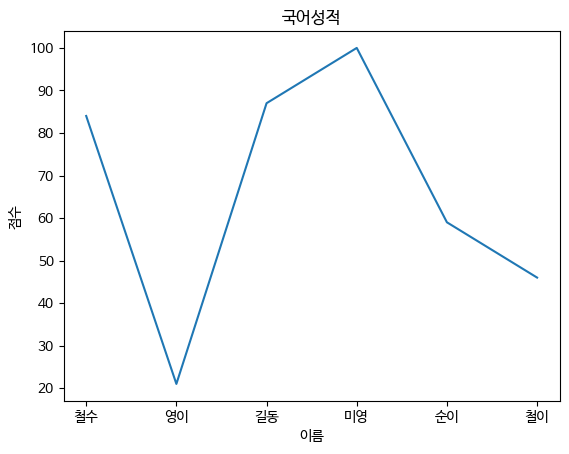

In [3]:
plt.plot(d1.index, d1['국어'])
plt.title('국어성적')
plt.xlabel('이름')
plt.ylabel('점수')
plt.show()

**꾸미기 옵션**

| 옵션 | 설명 |
|---|---|
| `'o'` | 점 그래프로 표현 |
| `marker=마커모양` | 마커 모양 (예: 'o', '+', '*', '.') |
| `markerfacecolor=색` | 마커 배경색 |
| `markersize=숫자` | 마커 크기 |
| `color=색` | 선의 색 |
| `linewidth=숫자` | 선의 두께 |
| `label=label이름` | label 지정 |

꾸미기 옵션을 이용하여 선 그래프를 다양하게 그려보기

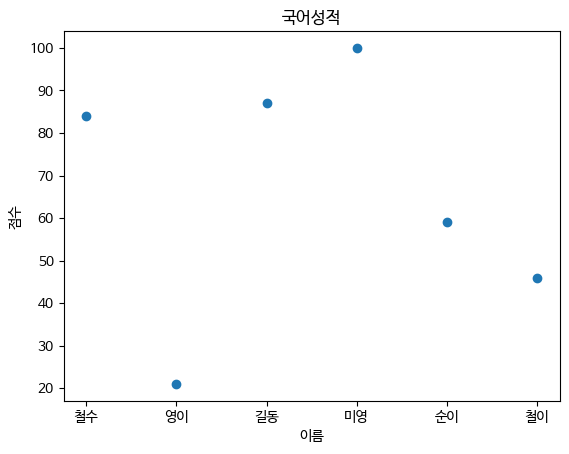

In [4]:
plt.plot(d1.index, d1['국어'], 'o')
plt.title('국어성적')
plt.xlabel('이름')
plt.ylabel('점수')
plt.show()

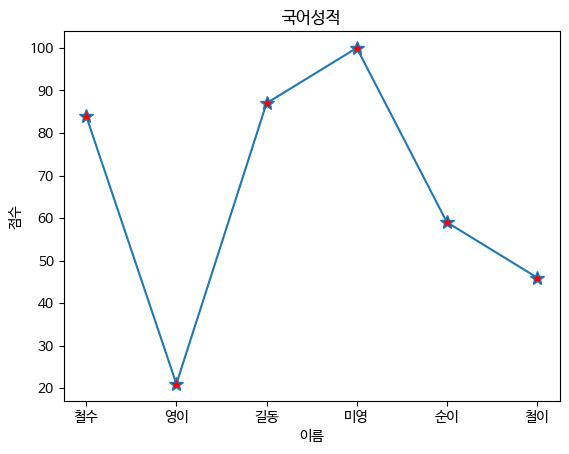

In [5]:
plt.plot(d1.index, d1['국어'],
         marker='*', markersize='10', markerfacecolor='red')
plt.title('국어성적')
plt.xlabel('이름')
plt.ylabel('점수')
plt.show()

**여러 개의 그래프 같이 보여주기**

`fig = plt.figure()` → `sub_plot = fig.add_subplot(행 크기, 열 크기, 그래프 위치)`

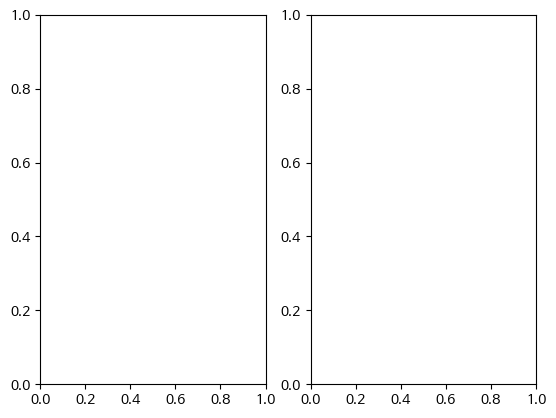

In [6]:
fig = plt.figure()
sub1 = fig.add_subplot(1,2,1)
sub2 = fig.add_subplot(1,2,2)

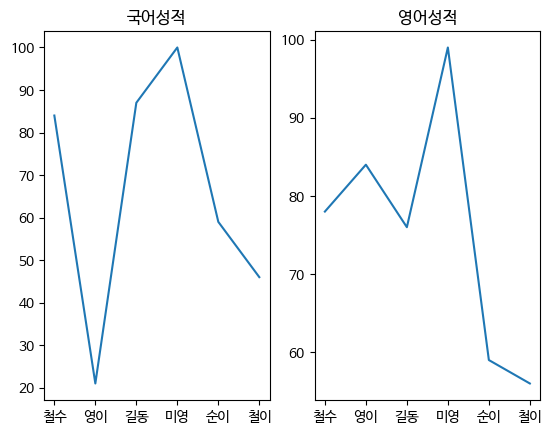

In [7]:
fig = plt.figure()
sub1 = fig.add_subplot(1,2,1)
sub2 = fig.add_subplot(1,2,2)
sub1.plot(d1.index, d1['국어'])
sub2.plot(d1.index, d1['영어'])
sub1.set_title('국어성적')
sub2.set_title('영어성적')
fig.show()

**(문제)** 국어, 영어, 수학 성적을 한 눈에 볼 수 있도록 선 그래프 그리기
— 그래프 사이즈 설정: `plt.figure(figsize=(가로, 세로))`

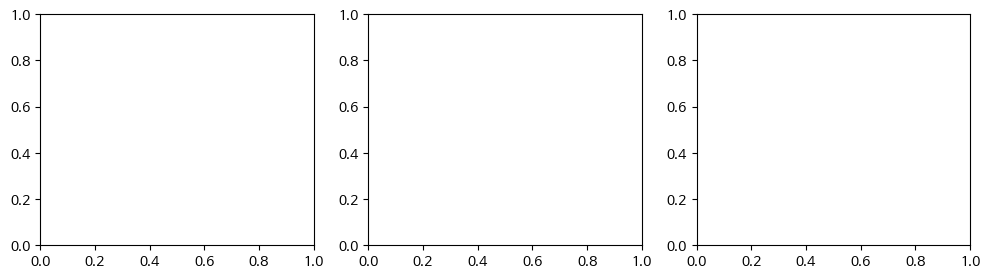

In [8]:
fig = plt.figure(figsize=(12,3))
sub1 = fig.add_subplot(1,3,1)
sub2 = fig.add_subplot(1,3,2)
sub3 = fig.add_subplot(1,3,3)

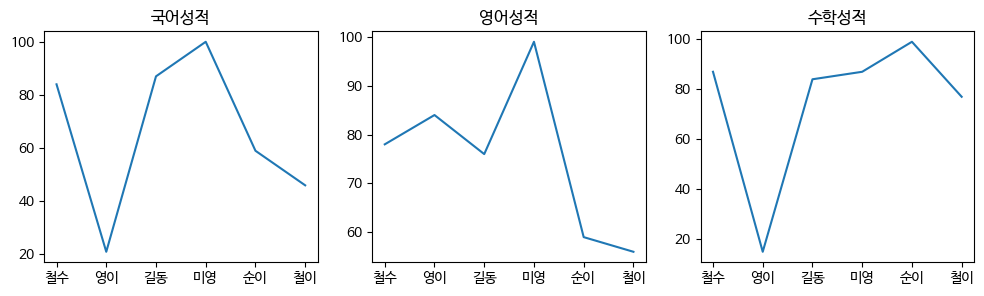

In [9]:
fig = plt.figure(figsize=(12,3))
sub1 = fig.add_subplot(1,3,1)
sub2 = fig.add_subplot(1,3,2)
sub3 = fig.add_subplot(1,3,3)
sub1.plot(d1.index, d1['국어'])
sub2.plot(d1.index, d1['영어'])
sub3.plot(d1.index, d1['수학'])
sub1.set_title('국어성적')
sub2.set_title('영어성적')
sub3.set_title('수학성적')
fig.show()

## 2강. 면적 그래프, 막대 그래프, 히스토그램

### 1. 면적 그래프(area plot)
선 그래프를 확장한 개념으로, 각 열의 패턴과 함께 열 전체의 합계가 어떻게 변하는지 파악할 수 있습니다.
- `DataFrame객체.plot(kind='area')`
- 누적 여부: `stacked=True/False` (기본값 True)
- 색의 투명도: `alpha=값` (0~1 범위)

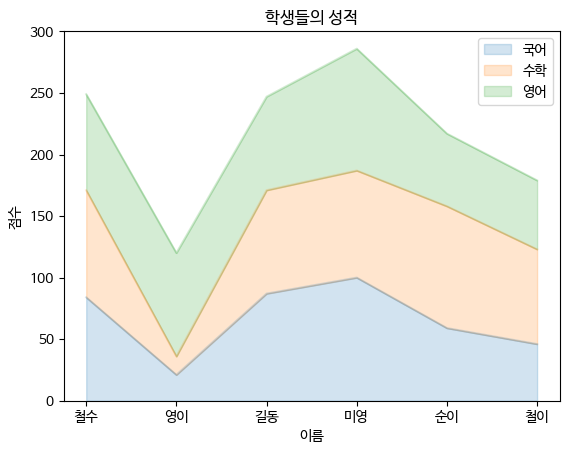

In [10]:
d1.plot(kind='area', alpha=0.2)
plt.title('학생들의 성적')
plt.xlabel('이름')
plt.ylabel('점수')
plt.show()

### 2. 막대 그래프(bar plot)
데이터 값의 크기에 비례하는 높이의 직사각형 막대로 표현합니다.
- 세로형(`kind='bar'`): 시계열 데이터 표현에 적합
- 가로형(`kind='barh'`): 변수 사이 값의 크기 차이 설명에 적합
- 색상 설정: `color=색상 리스트`

예시 – 세로형

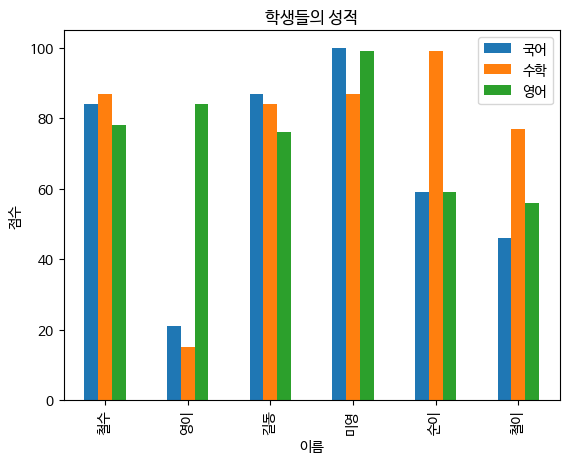

In [11]:
d1.plot(kind='bar')
plt.title('학생들의 성적')
plt.xlabel('이름')
plt.ylabel('점수')
plt.show()

예시 – 가로형

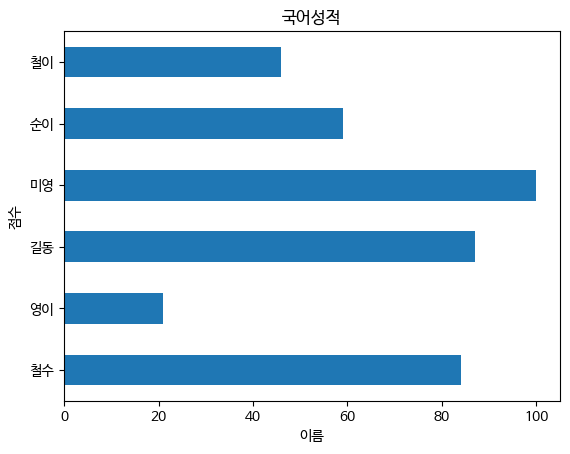

In [12]:
d1['국어'].plot(kind='barh')
plt.title('국어성적')
plt.ylabel('점수')
plt.xlabel('이름')
plt.show()

**(문제·풀이)** 국어 성적에 대한 세로 막대 그래프 그리기

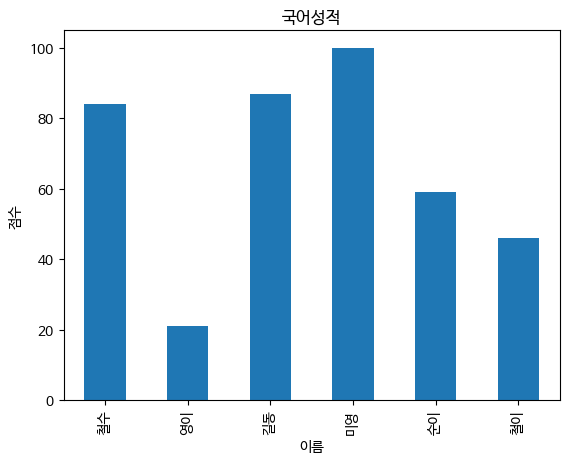

In [13]:
d1['국어'].plot(kind='bar')
plt.title('국어성적')
plt.ylabel('점수')
plt.xlabel('이름')
plt.show()

**(문제·풀이)** 데이터를 정렬하여, 수학 성적에 대한 가로 막대 그래프 그리기

In [14]:
sorted_math = d1.sort_values(by='수학', ascending=True)
sorted_math

,국어,수학,영어
영이,21,15,84
철이,46,77,56
길동,87,84,76
철수,84,87,78
미영,100,87,99
순이,59,99,59


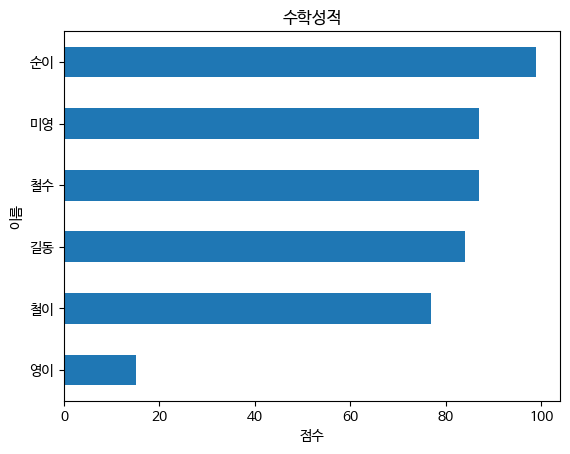

In [15]:
sorted_math['수학'].plot(kind='barh')
plt.title('수학성적')
plt.ylabel('이름')
plt.xlabel('점수')
plt.show()

### 3. 히스토그램(histogram)
변수가 하나인 단변수 데이터의 빈도수를 표현합니다. (x축: 같은 크기의 여러 구간, y축: 구간에 속하는 데이터 개수)
- `DataFrame객체['컬럼명'].plot(kind='hist')`
- 구간: `bins=숫자`

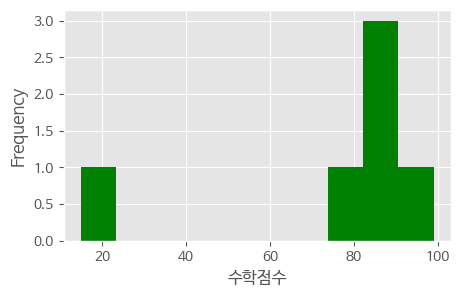

In [16]:
plt.style.use('ggplot')
d1['수학'].plot(kind='hist', bins=10, color='green', figsize=(5,3))
plt.xlabel('수학점수')
plt.show()

**(문제·풀이)** tips 데이터를 분석하여 'total_bill' 열의 데이터를 히스토그램으로 그리기

In [17]:
import seaborn as sns

tips = sns.load_dataset('tips')
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


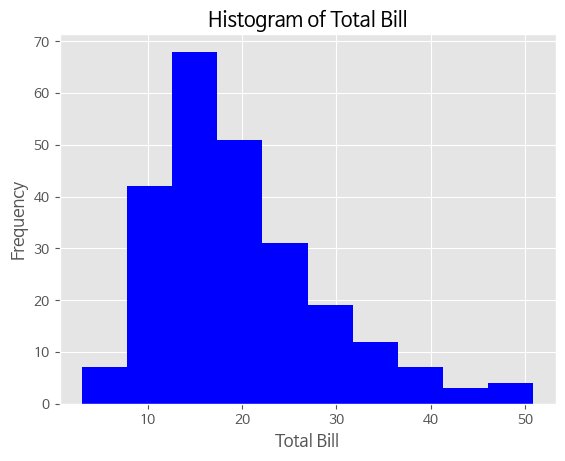

In [18]:
plt.style.use('ggplot')
tips['total_bill'].plot(kind='hist', bins=10, color='blue')
plt.xlabel('Total Bill')
plt.title('Histogram of Total Bill')
plt.show()

## 3강. 산점도, 파이 차트, 박스 플롯

### 1. 산점도(scatter plot)
서로 다른 두 변수 사이의 관계를 나타냅니다.
- `DataFrame객체.plot(kind='scatter', x=..., y=...)`

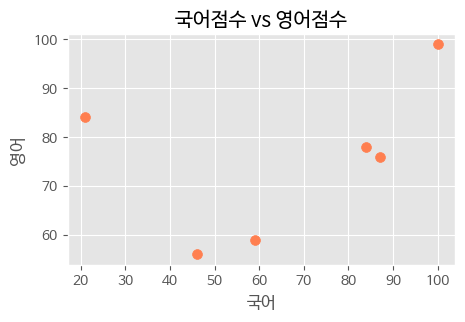

In [19]:
plt.style.use('ggplot')
d1.plot(kind='scatter', x='국어', y='영어', c='coral', s=50, figsize=(5,3))
plt.title('국어점수 vs 영어점수')
plt.show()

**(문제·풀이)** tips 데이터의 'total_bill'과 'tip' 열로 산점도 그리기

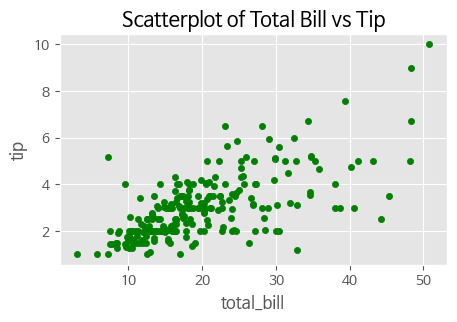

In [20]:
plt.style.use('ggplot')
tips.plot(kind='scatter', x='total_bill', y='tip', c='green', figsize=(5,3))
plt.title('Scatterplot of Total Bill vs Tip')
plt.show()

### 2. 파이 차트(pie chart)
원을 파이 조각처럼 나누어서 범주별 구성 비율을 표현합니다. — `plot(kind='pie')`

In [21]:
d1['성별'] = ['남','여','남','여','여','남']
d1['평균'] = [83,40,82,95,72,59]
d1['Pass/Fail'] = ['P','F','P','P','F','F']
d1['count'] = [1,1,1,1,1,1]
d1

,국어,수학,영어,성별,평균,Pass/Fail,count
철수,84,87,78,남,83,P,1
영이,21,15,84,여,40,F,1
길동,87,84,76,남,82,P,1
미영,100,87,99,여,95,P,1
순이,59,99,59,여,72,F,1
철이,46,77,56,남,59,F,1


In [22]:
grouped = d1.groupby(['성별','Pass/Fail'])
d2 = grouped[['count']].sum()
d2

count
성별 Pass/Fail       
남  F              1
   P              2
여  F              2
   P              1

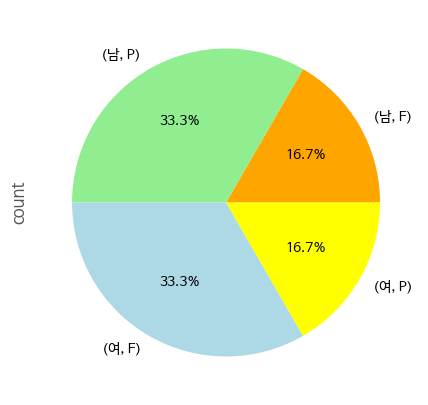

In [23]:
d2['count'].plot(kind='pie',
                 figsize=(7,5),
                 autopct='%.1f%%',
                 startangle=0,
                 colors=['orange','lightgreen','lightblue','yellow'])
plt.show()

### 3. 박스 플롯(boxplot)
범주형 데이터의 분포를 파악하는 데 적합하며, 5개의 통계 지표(최소값, 1사분위값, 중간값, 3사분위값, 최대값)를 제공합니다. — `plt.boxplot()`

/tmp/ipykernel_3389/575412753.py:2: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(x=[d1[d1['성별']=='남']['평균'],


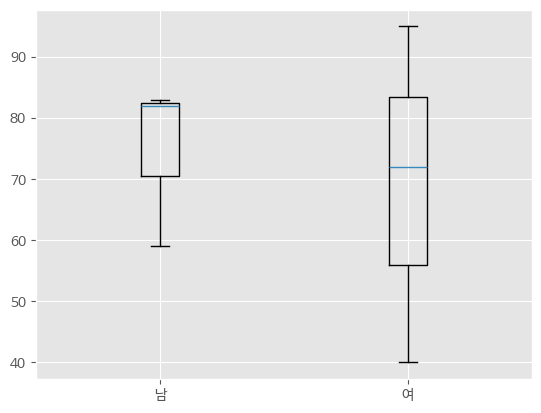

In [24]:
plt.style.use('ggplot')
plt.boxplot(x=[d1[d1['성별']=='남']['평균'],
               d1[d1['성별']=='여']['평균']],
            labels=['남','여'])
plt.show()

**(문제·풀이)** tips 데이터를 분석하여 성별로 tip의 분포를 보여주는 박스 플롯 나타내기

/tmp/ipykernel_3389/2807445217.py:2: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(x=[tips[tips['sex']=='Female']['tip'],


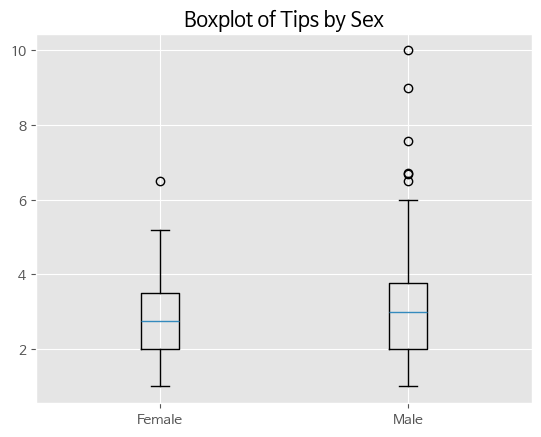

In [25]:
plt.style.use('ggplot')
plt.boxplot(x=[tips[tips['sex']=='Female']['tip'],
               tips[tips['sex']=='Male']['tip']],
            labels=['Female','Male'])
plt.title('Boxplot of Tips by Sex')
plt.show()